# Boundary Element Model

The Boundary Element Model (BEM) delimits the different compartments of the head (brain, skull, skin) by generating 3 different surfaces:
- the inner skull
- the outer skull
- the outer skin

The conductivity between these layers is homogeneous and anisotropic. <br>

The layers are obtained by extracting surfaces from the charm segmentation:
1. Generate a volumetric mask using the desired segmentation labels.
2. Apply a close morphological operator  to fill holes. This step decreases the precision but makes the surfaces compatible with MNE.
3. Extract the surfaces using marching cubes and remesh by wrapping an icosahedron sphere.

## 📦 Imports

In [5]:
import mindmap as mm 
import ants
import pyvista as pv 
import nibabel as nib
import mne
import numpy as np
import skimage
from scipy import ndimage

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `seg`: CHARM segmentation

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.

In [6]:
########### Parameters #############
fconfig = "../../papers/simf/configuration.yml"
subject = 1
####################################

# configuration
reader = mm.io.dataset_reader(fconfig)
data   = reader(subject, "seg")

# folders
fs_dir = reader.config["FS_DIR"]
mm_dir = reader.config["MM_DIR"]

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- seg
Missing objects:


#### ⚙️ <font color=green>**Generate volumetric masks**</font>
Generate volumetric masks of each layer (skin, outer skull and inner skull). 

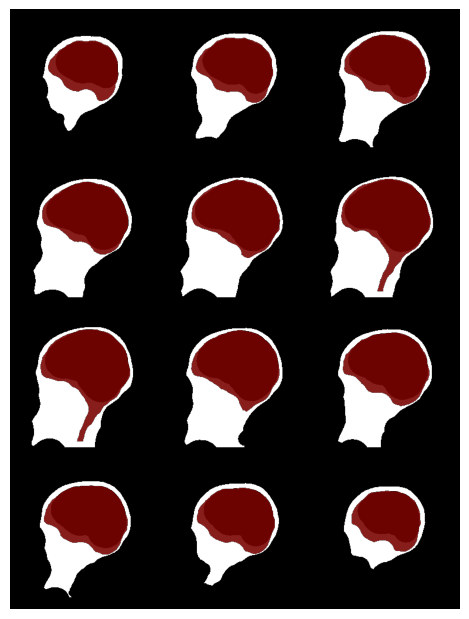

In [7]:
def make_bem_volumetric_masks(segmentation, closing_radius=20, return_skull=False):
    """
    Generate volumetric masks for BEM layers.

    Parameters
    ----------
    segmentation: mm.Parcellation
        Charm head segmentations.

    closing_radius: int
        Size of closing disk (number of voxels).

    return_skull: bool
        Whether to return skull mask.

    Returns
    -------
    skin: nib.Nifti1Image 
        Skin mask.

    oskull: nib.Nifti1Image 
        Outer skull mask.

    iskull: nib.Nifti1Image 
        Inner skull mask.

    skull: nib.Nifti1Image (optional)
        Skull mask.
    """
    # skin 
    skin = segmentation.create_mask([511])
    skin = mm.utils.nibabel_to_ants(skin)
    skin = skin.morphology("close", radius=closing_radius)
    skin[:,-10:,:] = 0
    skin[:,skin.shape[1]-11,:] = ndimage.binary_fill_holes(skin[:,skin.shape[1]-11,:].numpy())      # close bottom

    # skull
    skull = segmentation.create_mask([515])
    skull = mm.utils.nibabel_to_ants(skull)
    skull = skull.morphology("close", radius=5)

    # trim (used to trim inner skull for easy mesh)
    trim = segmentation.create_mask([501, 507, 509]) # other tissues/air/mucosa
    trim = mm.utils.nibabel_to_ants(trim)
    trim2 = skull.morphology("close", radius=100)

    # outer skull envelope
    oskull = skull.morphology("close", radius=30) 
    oskull[:,-20:,:] = 0

    # inner skull envelope
    iskull = trim2 * (1-skull) * (1-trim)
    iskull = iskull.get_mask()
    iskull = iskull.morphology("close", radius=20)
    iskull[:,-30:,:] = 0

    if return_skull:
        return skin, oskull, iskull, skull 
    else:
        return skin, oskull, iskull

skin, oskull, iskull, skull = make_bem_volumetric_masks(data["seg"], closing_radius=20, return_skull=True)
oskull.plot(overlay=iskull)

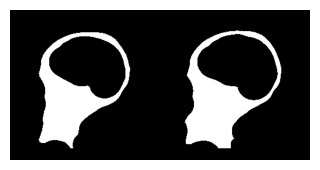

In [13]:
oskull.plot(slices=[100,105])

#### ⚙️ <font color=green>**Convert volumes to icosahedron surfaces**</font>

In [9]:
def vol_to_surf(volume, remesh=True, subdivision=4, compute_normals=True, apply_affine=True):
    """
    Generate mesh from volumetric mask.

    Parameters
    ----------
    volume: np.ndarray, ants, nibabel
        Volume mask.

    remesh: bool
        Whether to remesh into an icosahedral surface.

    subdivision: int = 4
        Icosahedral subdivision for template sphere. 

    compute_normals: bool = True
        Compute normals.

    apply_affine: bool = True
        If volume is an ants or nibabel object, apply affine to be in [mm] space.

    Returns
    -------
    mesh: pv.Polydata
        Surface mesh.
    """
    def get_affine(image: ants.ANTsImage):
        """
        Return the image affine from an ANTsImage object. 
        """
        spacing = image.spacing
        origin  = image.origin
        direction = image.direction

        affine = np.eye(4)
        affine[:3, :3] = np.diag(spacing) @ direction
        affine[:3, 3] = origin 

        affine[:2, :] *= -1    # flip y and z axis to be in nibabel convention

        return affine

    affine = None
    if isinstance(volume, ants.ANTsImage):
        affine = get_affine(volume)
        volume = volume.numpy()
    elif isinstance(volume, nib.Nifti1Image):
        affine = volume.affine
        volume = volume.get_fdata()

    # 1. -- Extract surface with marching cubes --
    verts, faces, _, _ = skimage.measure.marching_cubes(volume, level=0.5)
    mesh               = mm.utils.surf_to_polydata(verts, faces)
    mesh               = mesh.extract_largest()
    
    if remesh: 
        # 2. -- Create an icosphere mesh --
        center          = mesh.points.mean(axis=0)
        centered_mesh   = mesh.points - center 
        radius          = np.linalg.norm(centered_mesh, axis=1).max()

        icosphere = pv.Icosphere(radius, center, nsub=subdivision)

        # 3. -- Project icosphere vertices onto the original surface --
        # build direction vector from the center
        directions = icosphere.points - center 
        norms      = np.linalg.norm(directions, axis=1, keepdims=True)
        directions /= norms  

        # perform ray tracing
        points, rays, cells = mesh.multi_ray_trace(icosphere.points, -directions, first_point=True)
        idx                 = rays.argsort()    # order may be lost when using GPU
        new_points          = points[idx]

        # 4. -- Remesh surface --
        mesh = pv.PolyData(new_points, icosphere.faces)
    
    if apply_affine:
        if affine is not None:
            mesh.points = nib.affines.apply_affine(affine, mesh.points)

    if compute_normals:
        mesh = mesh.compute_normals(auto_orient_normals=True)

    return mesh


# extract surfaces
skin_   = vol_to_surf(skin, subdivision=4)
oskull_ = vol_to_surf(oskull, subdivision=4)
iskull_ = vol_to_surf(iskull, subdivision=4)
skull_  = vol_to_surf(skull, remesh=False)

# check manifold
print(f"Is skin manifold: {skin_.is_manifold}")
print(f"Is outer skull manifold: {oskull_.is_manifold}")
print(f"Is inner skull manifold: {iskull_.is_manifold}")

# plot
p = pv.Plotter(shape=(1,2))
p.add_mesh(skin_, color="white", opacity=0.1, show_edges=True)
p.add_mesh(oskull_, color="white", opacity=0.2, show_edges=True)
p.add_mesh(iskull_, color="white", opacity=1, show_edges=True)
p.add_title("BEM surfaces")

p.subplot(0,1)
p.add_mesh(skull_, color="white", smooth_shading=True)
p.add_title("High resolution skull mesh")

p.show()

Is skin manifold: True
Is outer skull manifold: True
Is inner skull manifold: True


Widget(value='<iframe src="http://localhost:44509/index.html?ui=P_0x7efb8c27bf10_0&reconnect=auto" class="pyvi…

💾 **Save surfaces in the FreeSurfer bem folder**

In [10]:
fs_dir = reader.config["FS_DIR"]

# save surfaces freesurfer format
fskin   = fs_dir/data["sub"]/"bem"/"outer_skin.surf"

fskin_better   = fs_dir/data["sub"]/"bem"/"outer_skin.surf"
foskull_better = fs_dir/data["sub"]/"bem"/"outer_skull.surf" 
fiskull_better = fs_dir/data["sub"]/"bem"/"inner_skull.surf" 

# write surfaces down 
_,_,metadata = nib.freesurfer.read_geometry(fskin, read_metadata=True)
mm.io.write_surface(fskin_better, skin_, metadata)
mm.io.write_surface(foskull_better, oskull_, metadata)
mm.io.write_surface(fiskull_better, iskull_, metadata)

🌟 **Visualize BEM and MRI**

Using surface: /media/nino/DATA/SIMF/derivatives/freesurfer/vepcon_sub-10/bem/inner_skull.surf
Using surface: /media/nino/DATA/SIMF/derivatives/freesurfer/vepcon_sub-10/bem/outer_skull.surf
Using surface: /media/nino/DATA/SIMF/derivatives/freesurfer/vepcon_sub-10/bem/outer_skin.surf


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/mne/viz/utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


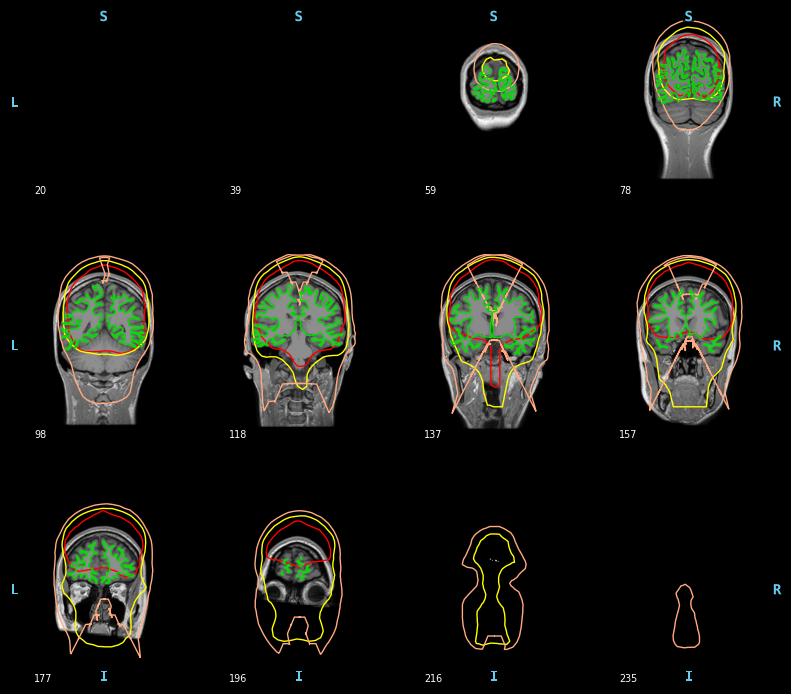

In [11]:
fs_dir = reader.config["FS_DIR"]

plot_bem_kwargs = dict(
    subject=data["sub"],
    subjects_dir=fs_dir,
    brain_surfaces="white",
    orientation="coronal",
)

fig = mne.viz.plot_bem(**plot_bem_kwargs)

#### ⚙️ **<font color=green>Create Conduction Model</font>**
In this section, we apply topological checks to verify if the surfaces are compatible with each other in order and apply electrical conductivities to each compartment

📤 **<font color=pink>Outputs</font>**
- Conductor Model (`head_model`)

🛠️ **<font color=violet>Model properties</font>**:
- `conductivities`: The 3 conductivities indicating the electrical conductivity in [S/cm] in each compartment.
    - The first value indicates the conductivity of the brain tissue.
    - The second value indicates the conductivity of the skull tissue.
    - The third value indicates the conductivity of the skin tissue.
- `resolution`: The resolution can be optimized for various subsampling level (`None`, `ico5`=20484, `ico4`=5120, `ico3`=1280). Subsampling using `ico5` or `None` contains to many datapoints and is unable to save. <br>

In [38]:
############# Parameters ################
# properties
conductivities = [0.3, 0.006, 0.3]
resolution     = None 
#########################################

model = mne.make_bem_model(
        subject      = data["sub"],
        subjects_dir = reader.config["FS_DIR"],
        conductivity = conductivities,
        ico          = resolution,
        verbose      = "warning",
)

bem  = mne.make_bem_solution(model, verbose="warning")

💾 **Save BEM** <br>
🛠️ **<font color=violet>Options</font>**:
- `overwrite`: Overwrite head model if already exists.
- `purpose`: Purpose of model (`inv` for solving inverse problem, `sim` for generating simulations). Will adapt the naming of the file.

In [39]:
######### Parameters ############
# options
overwrite = True 
purpose   = "inv"
#################################

if purpose == "inv":
    fbem = mm_dir/data["sub"]/"fwd"/f"{data['sub']}_bem.fif"
elif purpose == "sim":
    fbem = mm_dir/data["sub"]/"fwd"/f"{data['sub']}_sim_bem.fif"
else:
    raise ValueError(f"Uknown purpose '{purpose}'")

if not fbem.parent.exists():
    fbem.parent.mkdir(parents=True)

mne.write_bem_solution(fbem, bem, overwrite=overwrite, verbose="warning")
print(f"\033[92mSuccessfully saved {purpose} BEM solution for subject {data['sub']}\033[0m")

Successfully saved inv BEM solution for subject sub-pat25
